# Neural Networks from Scratch: Student Lab Notebook
**Course:** Foundations, Forward Propagation, Backpropagation & Optimization  
**Aligned with:** *Neural Networks from Scratch* Slide Deck (Sessions 1 & 2)

---

### Objectives
In this hands-on lab, you will build a complete 2-layer artificial neural network from scratch using only **NumPy**.
By the end of this lab, you will understand:
1. **Session 1 (Forward Propagation):**
   - How linear transformations ($Z = W \cdot X + b$) and activation functions (ReLU, Sigmoid, Tanh) work together.
   - How to construct the forward propagation pipeline and store intermediate variables in a `cache`.
   - How to compute prediction error using Mean Squared Error (MSE) and Cross-Entropy.
2. **Session 2 (Backpropagation & Training):**
   - How the calculus **Chain Rule** allows us to calculate gradients backwards from output to input.
   - How **Gradient Descent** updates weights to minimize loss.
   - How to train a neural network to solve the non-linear **XOR logic problem** and plot decision boundaries.


---
## Part 1: Lab 1 — Constructing the Forward Architecture (Slide 13 & 14)

### Task 1.1: Environment Setup
Import NumPy and Matplotlib for math and visualization.


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)
print(f"NumPy version: {np.__version__}")


NumPy version: 2.4.6


### Task 1.2: Activation Functions (Slide 5 & 6)
Implement the **Sigmoid**, **ReLU**, and **Tanh** activation functions:
- $\text{Sigmoid}(z) = \frac{1}{1 + e^{-z}}$
- $\text{ReLU}(z) = \max(0, z)$
- $\text{Tanh}(z) = \tanh(z)$


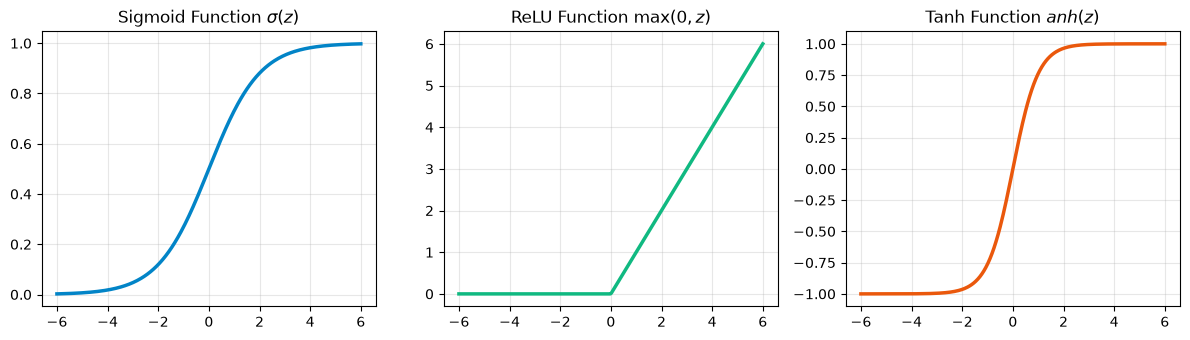

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    z_clipped = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z_clipped))

def relu(z):
    return np.maximum(0, z)

def tanh(z):
    return np.tanh(z)

# Let's plot the activation functions side-by-side
z_vals = np.linspace(-6, 6, 300)
plt.figure(figsize=(12, 3.5))

plt.subplot(1, 3, 1)
plt.plot(z_vals, sigmoid(z_vals), color='#0284c7', lw=2.5)
plt.title("Sigmoid Function $\sigma(z)$")
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(z_vals, relu(z_vals), color='#10b981', lw=2.5)
plt.title("ReLU Function $\max(0, z)$")
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
plt.plot(z_vals, tanh(z_vals), color='#ea580c', lw=2.5)
plt.title("Tanh Function $\tanh(z)$")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Task 1.3: Parameter Initialization (Slide 14)
Write a function `initialize_parameters(n_x, n_h, n_y)` to randomly initialize weights $W_1, W_2$ and zero-initialize biases $b_1, b_2$ with the correct matrix dimensions:
- $W_1 \in \mathbb{R}^{n_h \times n_x}$
- $b_1 \in \mathbb{R}^{n_h \times 1}$
- $W_2 \in \mathbb{R}^{n_y \times n_h}$
- $b_2 \in \mathbb{R}^{n_y \times 1}$


In [6]:
import numpy as np

def initialize_parameters(n_x, n_h, n_y, seed=42):
    """
    Initializes weights and biases with scaled random normal distribution.
    """
    if seed is not None:
        np.random.seed(seed)
        
    W1 = np.random.randn(n_h, n_x) * np.sqrt(2.0 / n_x)
    b1 = np.zeros((n_h, 1))
    W2 = np.random.randn(n_y, n_h) * np.sqrt(2.0 / n_h)
    b2 = np.zeros((n_y, 1))
    
    return W1, b1, W2, b2

# Test initialization for a network with 2 inputs, 4 hidden units, 1 output
W1_init, b1_init, W2_init, b2_init = initialize_parameters(n_x=2, n_h=4, n_y=1)
print("W1 shape:", W1_init.shape, "(Expected: 4, 2)")
print("b1 shape:", b1_init.shape, "(Expected: 4, 1)")
print("W2 shape:", W2_init.shape, "(Expected: 1, 4)")
print("b2 shape:", b2_init.shape, "(Expected: 1, 1)")


W1 shape: (4, 2) (Expected: 4, 2)
b1 shape: (4, 1) (Expected: 4, 1)
W2 shape: (1, 4) (Expected: 1, 4)
b2 shape: (1, 1) (Expected: 1, 1)


### Task 1.4: Forward Propagation Pipeline (Slide 9 & 10)
Combine the linear steps and activations into the forward pass:
$$Z_1 = W_1 \cdot X + b_1$$
$$A_1 = \text{ReLU}(Z_1)$$
$$Z_2 = W_2 \cdot A_1 + b_2$$
$$A_2 = \text{Sigmoid}(Z_2)$$
Remember to save $(Z_1, A_1, Z_2, A_2)$ in a cache for backpropagation!


In [7]:
import numpy as np

def forward_prop(X, W1, b1, W2, b2, activation="relu"):
    """
    2-Layer Forward Propagation Pipeline (Slide 10).
    """
    # Layer 1
    Z1 = np.dot(W1, X) + b1
    if activation == "relu":
        A1 = relu(Z1)
    elif activation == "tanh":
        A1 = tanh(Z1)
    else:
        A1 = sigmoid(Z1)
        
    # Layer 2
    Z2 = np.dot(W2, A1) + b2
    A2 = sigmoid(Z2)
    
    # Store values for backprop
    cache = (Z1, A1, Z2, A2)
    return A2, cache

# Test forward propagation with dummy batch of 4 samples (2 features each)
X_dummy = np.array([[0.5, 0.1, -0.4, 0.9],
                    [-0.2, 0.8, 0.3, -0.7]])
A2_test, cache_test = forward_prop(X_dummy, W1_init, b1_init, W2_init, b2_init)
print("Output A2 predictions shape:", A2_test.shape, "(Expected: 1, 4)")
print("Output A2 values:", np.round(A2_test, 4))


Output A2 predictions shape: (1, 4) (Expected: 1, 4)
Output A2 values: [[0.4271 0.5592 0.517  0.3842]]


### Task 1.5: Loss Functions (Slide 11 & 12)
Implement Mean Squared Error (MSE):
$$L = \frac{1}{2m} \sum_{i=1}^m (\hat{Y}^{(i)} - Y^{(i)})^2$$


In [8]:
import numpy as np

def mse_loss(Y_hat, Y):
    """Mean Squared Error Loss (Slide 12)."""
    m = Y.shape[1]
    error = (Y_hat - Y) ** 2
    loss = (1.0 / (2.0 * m)) * np.sum(error)
    return float(loss)

Y_dummy = np.array([[1.0, 0.0, 0.0, 1.0]])
loss_test = mse_loss(A2_test, Y_dummy)
print(f"Initial dummy loss: {loss_test:.6f}")


Initial dummy loss: 0.160939


---
## Part 2: Lab 2 — Training and Evaluating the Network (Slide 27 & 28)

### Task 2.1: Backpropagation Gradients (Slide 22 & 23)
Using the calculus chain rule, compute derivatives backwards through the layers:
- Layer 2 gradients:
  $$dZ_2 = A_2 - Y$$
  $$dW_2 = \frac{1}{m} dZ_2 \cdot A_1^T$$
  $$db_2 = \frac{1}{m} \sum dZ_2$$
- Layer 1 gradients:
  $$dZ_1 = (W_2^T \cdot dZ_2) \odot (Z_1 > 0)$$
  $$dW_1 = \frac{1}{m} dZ_1 \cdot X^T$$
  $$db_1 = \frac{1}{m} \sum dZ_1$$


In [9]:
import numpy as np

def backward_prop(X, Y, cache, W2, activation="relu"):
    """
    Calculates parameter gradients using chain rule (Slide 23).
    """
    Z1, A1, Z2, A2 = cache
    m = X.shape[1]
    
    # Layer 2 gradients
    dZ2 = A2 - Y
    dW2 = (1.0 / m) * np.dot(dZ2, A1.T)
    db2 = (1.0 / m) * np.sum(dZ2, axis=1, keepdims=True)
    
    # Layer 1 gradients (includes ReLU derivative)
    if activation == "relu":
        d_act = (Z1 > 0).astype(float)
    elif activation == "tanh":
        d_act = 1.0 - np.square(A1)
    else:
        d_act = A1 * (1.0 - A1)
        
    dZ1 = np.dot(W2.T, dZ2) * d_act
    dW1 = (1.0 / m) * np.dot(dZ1, X.T)
    db1 = (1.0 / m) * np.sum(dZ1, axis=1, keepdims=True)
    
    return dW1, db1, dW2, db2


### Task 2.2: Gradient Descent Parameter Update (Slide 19 & 20)
Update parameters:
$$W = W - \alpha \cdot dW$$
$$b = b - \alpha \cdot db$$


In [10]:
import numpy as np

def update_params(W, b, dW, db, alpha):
    """Parameter Update with Gradient Descent (Slide 20)."""
    W_new = W - alpha * dW
    b_new = b - alpha * db
    return W_new, b_new


### Task 2.3: The Non-Linear XOR Logic Problem (Slide 28)
Create the XOR truth table:
- $(0, 0) \to 0$
- $(0, 1) \to 1$
- $(1, 0) \to 1$
- $(1, 1) \to 0$


In [11]:
import numpy as np

# Non-linear XOR logic dataset (Slide 28)
X_xor = np.array([
    [0.0, 0.0, 1.0, 1.0],
    [0.0, 1.0, 0.0, 1.0]
])
Y_xor = np.array([
    [0.0, 1.0, 1.0, 0.0]
])

print("XOR Inputs X (shape 2, 4):\n", X_xor)
print("XOR Targets Y (shape 1, 4):\n", Y_xor)


XOR Inputs X (shape 2, 4):
 [[0. 0. 1. 1.]
 [0. 1. 0. 1.]]
XOR Targets Y (shape 1, 4):
 [[0. 1. 1. 0.]]


### Task 2.4: The Training Loop (Slide 24 & 25)
Combine all components into the full training loop and train for 1000 epochs.


In [12]:
import numpy as np

# Full Training Loop (Slide 25)
epochs = 1000
alpha = 0.8
n_h = 4

# Initialize
W1, b1, W2, b2 = initialize_parameters(n_x=2, n_h=n_h, n_y=1, seed=42)
loss_history = []

for i in range(1, epochs + 1):
    # 1. Forward Pass
    A2, cache = forward_prop(X_xor, W1, b1, W2, b2, activation="relu")
    
    # 2. Compute Loss
    loss = mse_loss(A2, Y_xor)
    loss_history.append(loss)
    
    # 3. Backward Pass
    dW1, db1, dW2, db2 = backward_prop(X_xor, Y_xor, cache, W2, activation="relu")
    
    # 4. Update Weights
    W1, b1 = update_params(W1, b1, dW1, db1, alpha)
    W2, b2 = update_params(W2, b2, dW2, db2, alpha)
    
    # Print progress every 100 epochs
    if i % 100 == 0 or i == 1:
        preds = (A2 > 0.5).astype(int)
        acc = np.mean(preds == Y_xor) * 100
        print(f"Epoch {i:4d}/{epochs} | Loss: {loss:.6f} | Accuracy: {acc:.1f}%")


Epoch    1/1000 | Loss: 0.128629 | Accuracy: 75.0%
Epoch  100/1000 | Loss: 0.004669 | Accuracy: 100.0%
Epoch  200/1000 | Loss: 0.000436 | Accuracy: 100.0%
Epoch  300/1000 | Loss: 0.000137 | Accuracy: 100.0%
Epoch  400/1000 | Loss: 0.000064 | Accuracy: 100.0%
Epoch  500/1000 | Loss: 0.000037 | Accuracy: 100.0%
Epoch  600/1000 | Loss: 0.000023 | Accuracy: 100.0%
Epoch  700/1000 | Loss: 0.000016 | Accuracy: 100.0%
Epoch  800/1000 | Loss: 0.000012 | Accuracy: 100.0%
Epoch  900/1000 | Loss: 0.000009 | Accuracy: 100.0%
Epoch 1000/1000 | Loss: 0.000007 | Accuracy: 100.0%


### Task 2.5: Verifying Predictions & Plotting Loss Curve
Check the network's final predictions on the XOR dataset and visualize the loss reduction curve.


Ground Truth Targets:     [0 1 1 0]
Model Output Probability: [7.300e-03 9.988e-01 9.988e-01 9.000e-04]
Final Class Predictions:  [0 1 1 0]


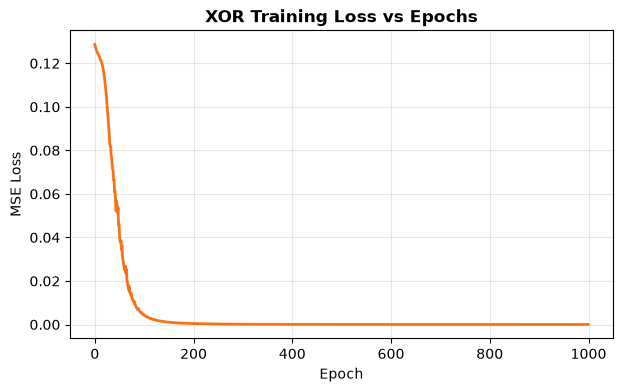

In [13]:
import numpy as np
import matplotlib.pyplot as plt

A2_final, _ = forward_prop(X_xor, W1, b1, W2, b2, activation="relu")
print("Ground Truth Targets:    ", Y_xor[0].astype(int))
print("Model Output Probability:", np.round(A2_final[0], 4))
print("Final Class Predictions: ", (A2_final[0] > 0.5).astype(int))

# Plot loss curve
plt.figure(figsize=(7, 4))
plt.plot(loss_history, color='#f97316', lw=2)
plt.title("XOR Training Loss vs Epochs", fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.grid(True, alpha=0.3)
plt.show()


### Task 2.6: Visualizing the Decision Boundary
Let's evaluate every coordinate in $[-0.2, 1.2] \times [-0.2, 1.2]$ to see the non-linear decision boundary learned by the neural network!


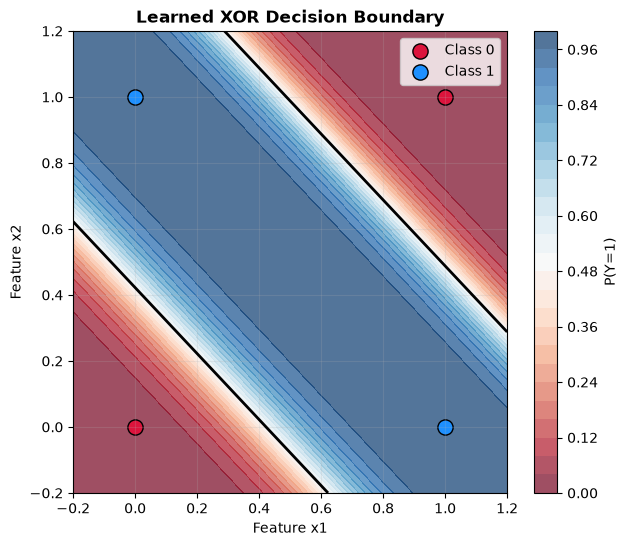

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Create dense 2D grid
xx, yy = np.meshgrid(np.linspace(-0.2, 1.2, 200), np.linspace(-0.2, 1.2, 200))
grid_points = np.vstack([xx.ravel(), yy.ravel()])

grid_preds, _ = forward_prop(grid_points, W1, b1, W2, b2, activation="relu")
grid_preds = grid_preds.reshape(xx.shape)

plt.figure(figsize=(7, 6))
plt.contourf(xx, yy, grid_preds, levels=30, cmap="RdBu", alpha=0.7)
plt.colorbar(label="P(Y=1)")

# Plot the 4 XOR data points
plt.scatter(X_xor[0, Y_xor[0] == 0], X_xor[1, Y_xor[0] == 0], c="crimson", s=120, edgecolors="k", label="Class 0")
plt.scatter(X_xor[0, Y_xor[0] == 1], X_xor[1, Y_xor[0] == 1], c="dodgerblue", s=120, edgecolors="k", label="Class 1")
plt.contour(xx, yy, grid_preds, levels=[0.5], colors="black", linewidths=2)

plt.title("Learned XOR Decision Boundary", fontweight="bold")
plt.xlabel("Feature x1")
plt.ylabel("Feature x2")
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()


---
## Student Discussion Questions & Takeaways
1. **The XOR Challenge:** Why is a multi-layer neural network required to solve XOR, whereas a single perceptron fails?
2. **Learning Rate Sensitivity:** What happens if you change $\alpha$ to `0.01` or `5.0`?
3. **Activation Function Choice:** Repeat the training with `activation="sigmoid"` instead of `"relu"`. How does the convergence speed compare?
